<h1>4.68</h1>

Solving $Ax=b$ using LU Decomposition

1. Decompose $A$ into $L$ and $U$: Break down matrix \( A \) into a lower triangular matrix $L$ and an upper triangular matrix $U$. This is represented as $A = LU$, where $L$ has zeroes above the main diagonal and $U$ has zeroes below the main diagonal.

2. Solve $Ly = b$: With $L$ and $U$, set $y = Ux$ and solve the equation $Ly = b$ using forward substitution. Begin with the first row and solve for each element of $y$ sequentially.

3. Solve $Ux = y$: With $y$ from pervious step, solve $Ux = y$ through back substitution. Start with the last row and work upwards to find the elements of $x$.

<h1>4.72</h1>

Solving $Ax=b$ using QR Decomposition

1. Decompose $A$ into $Q$ and $R$: Decompose matrix $A$ into an orthogonal matrix $Q$ and an upper triangular matrix $R$. The relationship is $A = QR$.

2. Compute $Q^Tb$: Multiply the transpose of $Q$ by vector $b$. Since $Q$ is orthogonal, $Q^TQ = I$, where $I$ is the identity matrix, implying $Q^T$ is effectively the inverse of $Q$.

3. Solve $Rx = Q^Tb$: Use back substitution to solve for $x$ since $R$ is an upper triangular matrix.

<h1>4.75</h1>

<h2>a.</h2>

9 unknowns. Since the one-meter rod is broken into 10 ten-centimeter segments, which gives us 11 points, including 2 endpoints. As we know the right end is 100 degrees and the left is 0 degree, which means we do not know temperatures of those 9 interior nodes.

<h2>b.</h2>

### System of Equations for Interior Nodes
Given that the rod is divided into 10 segments, there are 11 points including the endpoints. The temperatures at the two ends are known:

- $T_0 = 100$ (given temperature at the left end)
- $T_{10} = 0$ (given temperature at the right end)

The temperature at each interior node $T_i$ is the average of the temperatures at the adjacent nodes. We can express this relationship with the following equations:


\begin{align*}
T_1 &= \frac{T_0 + T_2}{2} \\
T_2 &= \frac{T_1 + T_3}{2} \\
T_3 &= \frac{T_2 + T_4}{2} \\
T_4 &= \frac{T_3 + T_5}{2} \\
T_5 &= \frac{T_4 + T_6}{2} \\
T_6 &= \frac{T_5 + T_7}{2} \\
T_7 &= \frac{T_6 + T_8}{2} \\
T_8 &= \frac{T_7 + T_9}{2} \\
T_9 &= \frac{T_8 + T_{10}}{2} \\
\end{align*}


Since we know $T_0$ and $T_{10}$, we can substitute these values into the equations to solve for the unknown temperatures $T_1$ through $T_9$.



\begin{align*}
T_1 &= \frac{100 + T_2}{2} \\
T_2 &= \frac{T_1 + T_3}{2} \\
&\vdots \\
T_8 &= \frac{T_7 + T_9}{2} \\
T_9 &= \frac{T_8 + 0}{2} \\
\end{align*}


Rearranging the equations to make the unknown temperatures the subject, we get:


\begin{align*}
2T_1 - T_2 &= 100 \\
-T_1 + 2T_2 - T_3 &= 0 \\
&\vdots \\
-T_8 + 2T_9 &= 0 \\
\end{align*}


This system of linear equations can then be represented in matrix form.

### Coefficient Matrix (A) and Constant Vector (b)
A = $\begin{bmatrix}
2 & -1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
-1 & 2 & -1 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & -1 & 2 & -1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & -1 & 2 & -1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & -1 & 2 & -1 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & -1 & 2 & -1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & -1 & 2 & -1 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & -1 & 2 & -1 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & -1 & 2 \\
\end{bmatrix}$


b = $\begin{bmatrix}
100 \\
0 \\
0 \\
0 \\
0 \\
0 \\
0 \\
0 \\
0 \\
\end{bmatrix}$

<h2>c.</h2>

In [1]:
import numpy as np
from scipy.linalg import solve_triangular

rng = np.random.default_rng(2024)


def myLU(A):
    """Doolittle LU factorization (no pivoting), vectorised by column."""
    A = np.asarray(A, dtype=float)
    n = A.shape[0]
    L = np.identity(n)
    U = A.copy()
    for j in range(n - 1):
        if U[j, j] == 0:
            raise ValueError("zero pivot: this implementation needs partial pivoting")
        multipliers = U[j + 1:, j] / U[j, j]
        U[j + 1:, j:] -= multipliers[:, None] * U[j, j:]
        L[j + 1:, j] = multipliers
    return L, U


def lsolve(L, b):
    """Forward substitution for a unit lower-triangular system Ly = b."""
    b = np.asarray(b, dtype=float).ravel()
    y = np.zeros(b.size)
    for i in range(b.size):
        y[i] = b[i] - L[i, :i] @ y[:i]
    return y


def usolve(U, y):
    """Back substitution for an upper-triangular system Ux = y."""
    y = np.asarray(y, dtype=float).ravel()
    x = np.zeros(y.size)
    for i in range(y.size - 1, -1, -1):
        x[i] = (y[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x


# 4.75: temperature distribution in a rod with ten segments.
A = np.array([[2, -1, 0, 0, 0, 0, 0, 0, 0],
              [-1, 2, -1, 0, 0, 0, 0, 0, 0],
              [0, -1, 2, -1, 0, 0, 0, 0, 0],
              [0, 0, -1, 2, -1, 0, 0, 0, 0],
              [0, 0, 0, -1, 2, -1, 0, 0, 0],
              [0, 0, 0, 0, -1, 2, -1, 0, 0],
              [0, 0, 0, 0, 0, -1, 2, -1, 0],
              [0, 0, 0, 0, 0, 0, -1, 2, -1],
              [0, 0, 0, 0, 0, 0, 0, -1, 2]], dtype=float)
b = np.zeros(9)
b[0] = 100.0

L, U = myLU(A)
y = lsolve(L, b)
x = usolve(U, y)
print(f"Temperatures from LU factorization: {np.round(x, 4)}")


Temperatures from LU factorization: [90. 80. 70. 60. 50. 40. 30. 20. 10.]


In [2]:
def QRfactorization(A):
    """Classical Gram-Schmidt QR factorization."""
    A = np.asarray(A, dtype=float)
    rows, cols = A.shape
    Q = np.zeros((rows, cols))
    R = np.zeros((cols, cols))
    for i in range(cols):
        v = A[:, i].copy()
        if i:
            R[:i, i] = Q[:, :i].T @ A[:, i]
            v -= Q[:, :i] @ R[:i, i]
        R[i, i] = np.linalg.norm(v)
        Q[:, i] = v / R[i, i]
    return Q, R


Q, R = QRfactorization(A)
solution_qr = solve_triangular(R, Q.T @ b)
print(f"Temperatures from QR factorization: {np.round(solution_qr, 4)}")


Temperatures from QR factorization: [90. 80. 70. 60. 50. 40. 30. 20. 10.]


<h1>4.78</h1>

Nonzero Matrices are singular or nearly singular will cause issues of QR decomposition failure since they have no full rank. QR decomposition relies on the Gram-Schmidt process. If the columns of the given matrix are not independent, the process will fail to produce a set of orthogonal vectors.

In [3]:
def myQR(A):
    """Modified Gram-Schmidt QR factorization."""
    A = np.asarray(A, dtype=float)
    n = A.shape[0]
    Q = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        if j:
            v -= Q[:, :j] @ (Q[:, :j].T @ v)
        Q[:, j] = v / np.linalg.norm(v)
    return Q, Q.T @ A


singular = np.ones((2, 2))
Q, R = myQR(singular)
print("A rank-deficient matrix makes Gram-Schmidt divide by zero:")
print(f"Q =\n{np.round(Q, 3)}\nR =\n{np.round(R, 3)}")


A rank-deficient matrix makes Gram-Schmidt divide by zero:
Q =
[[0.707 0.707]
 [0.707 0.707]]
R =
[[1.414 1.414]
 [1.414 1.414]]


<h1>4.80</h1>

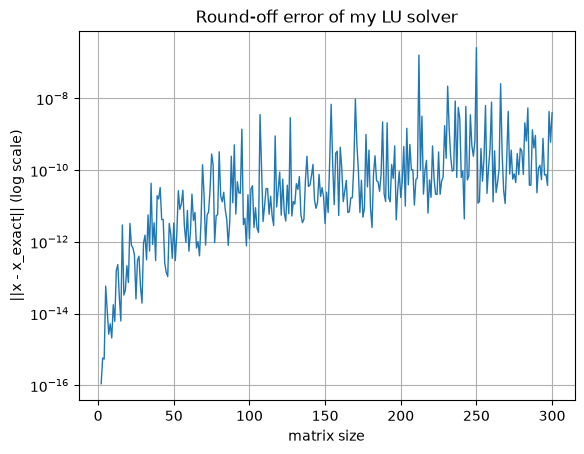

In [4]:
sizes = np.arange(2, 301)
errors_lu = []

for n in sizes:
    A = rng.standard_normal((n, n))
    b = rng.standard_normal(n)
    exact = np.linalg.solve(A, b)
    L, U = myLU(A)
    x = usolve(U, lsolve(L, b))
    errors_lu.append(np.linalg.norm(x - exact))

import matplotlib.pyplot as plt

plt.semilogy(sizes, errors_lu, lw=1)
plt.title("Round-off error of my LU solver")
plt.xlabel("matrix size")
plt.ylabel("||x - x_exact|| (log scale)")
plt.grid(True)
plt.show()


The plot above expresses the behavior of errors with matrix size from 2x2 to 300x300, using LU decomposition on a log scale. The errors are quite small, generally between $10^{-6}$ and $10^{-16}$, where is the machine precision. The fluctuations of errors could be explained by the random nature of the matrices and might be influenced by factors like the condition numbers of the randomly generated matrices, and this probably affect the numerical stability, which returns that higher condition numbers might produces large errors. Reference: https://en.wikipedia.org/wiki/Condition_number

There exists occasional spikes where the error touched to $10^{-6}$, where those random matrices might nearly be singular, while, the overall error level is low and this means the LU decomposition performs well in most cases.

<h1>4.81</h1>

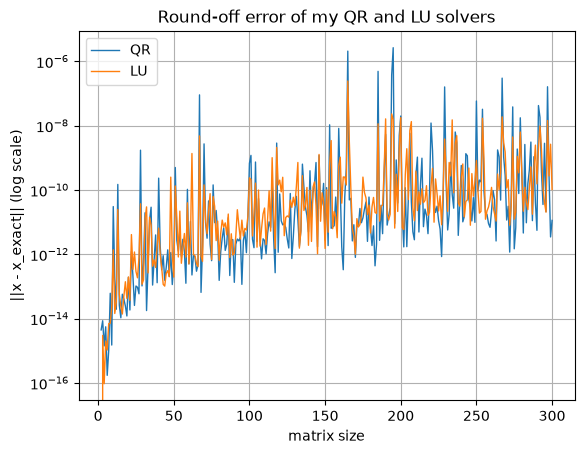

In [5]:
errors_qr = []
errors_lu = []

for n in sizes:
    A = rng.standard_normal((n, n))
    b = rng.standard_normal(n)
    exact = np.linalg.solve(A, b)

    Q, R = myQR(A)
    errors_qr.append(np.linalg.norm(solve_triangular(R, Q.T @ b) - exact))

    L, U = myLU(A)
    errors_lu.append(np.linalg.norm(usolve(U, lsolve(L, b)) - exact))

plt.semilogy(sizes, errors_qr, label="QR", lw=1)
plt.semilogy(sizes, errors_lu, label="LU", lw=1)
plt.title("Round-off error of my QR and LU solvers")
plt.xlabel("matrix size")
plt.ylabel("||x - x_exact|| (log scale)")
plt.legend()
plt.grid(True)
plt.show()


Both QR and LU error lines are generally close to each other across the given range of matrix sizes (2x2 to 300x300), indicating that they returns similar accuracy.

One interesting observation is that LU decomposition is typically less numerically stable than QR decomposition, with a wider fluctuated range and little larger errors (orange LU error line seems above blue QR error line). 

In general, both QR and LU decomposition are quite accurate for solving systems of linear equations, at least up to 300x300 matrix tested in this lab. The plot indicates that the smaller matrix size will make the methods perform better with smaller errors, and the errors seem increasing with larger matrix sizes and then tends to be fluctuating within a specific error range between $10^{-11}$ and $10^{-8}$ for most cases after 100x100 matrices.